## Посмотреть на каких карточках можно гонять

In [1]:
import csv
import io
import subprocess

fields = ["index", "name", "memory.total", "memory.used", "utilization.gpu", "temperature.gpu"]

result = subprocess.run(
    ["nvidia-smi", f"--query-gpu={','.join(fields)}", "--format=csv,noheader"],
    capture_output=True,
    text=True,
    check=True,
    timeout=15,
)

for row in csv.reader(io.StringIO(result.stdout), skipinitialspace=True):
    gpu = dict(zip(fields, row))

    print(f"GPU {gpu['index']}: {gpu['name']}")
    print(f"  Память:     {gpu['memory.used']} / {gpu['memory.total']}")
    print(f"  Загрузка:   {gpu['utilization.gpu']}")
    print(f"  Температура: {gpu['temperature.gpu']} °C")
    print()

GPU 0: NVIDIA RTX A4000
  Память:     13941 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 29 °C

GPU 1: NVIDIA RTX A4000
  Память:     15613 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 28 °C

GPU 2: NVIDIA RTX A4000
  Память:     12242 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 28 °C

GPU 3: NVIDIA RTX A4000
  Память:     10979 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 28 °C

GPU 4: NVIDIA RTX A4000
  Память:     10017 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 25 °C

GPU 5: NVIDIA RTX A4000
  Память:     9722 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 25 °C

GPU 6: NVIDIA RTX A4000
  Память:     8137 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 68 °C



## Всякие константы для бенчей

In [2]:
import torch
import torch.nn.functional as nn
from triton.testing import do_bench

device = torch.device("cuda:6")
torch.cuda.set_device(device)

N = 1 << 20
# N = 50

DTYPE = torch.float32
SEED = 42
WARMUP_MS = 25
REPEAT_MS = 100
RTOL = 1e-5
ATOL = 1e-6

In [3]:
import importlib

# importlib.reload(some_func)

In [4]:
import triton_impl

def triton_residual_rms_norm(x, residual, weight, eps=1e-6):
    return triton_impl.residual_rms_norm(x, residual, weight, eps=eps)

def torch_residual_rms_norm(x, residual, weight, eps=1e-6):
    y = x + residual

    res = nn.rms_norm(
        y,
        (y.shape[-1],),
        weight=weight,
        eps=eps,
    )

    return res

x = torch.randn(N, device=device, dtype=torch.float32)
residual = torch.zeros_like(x)
weight = torch.ones_like(x)

print(triton_residual_rms_norm(x, residual, weight))
print(torch_residual_rms_norm(x, residual, weight))

tensor([ 23.1902, 155.1828, -23.2570,  ..., -11.8973, 110.1079, -96.7373],
       device='cuda:6')
tensor([ 0.3940,  2.6366, -0.3951,  ..., -0.1768,  1.6363, -1.4376],
       device='cuda:6')


## Подгрузить построение графиков

In [5]:
%matplotlib inline

import sys
from pathlib import Path
import matplotlib.pyplot as plt

project_root = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "neuroslop" / "visualize_bench_results.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from neuroslop.visualize_bench_results import plot_benchmark

## Подгружаем CUDA C++ код

In [6]:
import os

os.environ["CUDA_HOME"] = "/usr/local/cuda-13.3"
os.environ["TORCH_CUDA_ARCH_LIST"] = "8.6"
os.environ["MAX_JOBS"] = "16"

from torch.utils.cpp_extension import load

cuda_module = load(
    name="cuda_vector_add",
    sources=[
        "/home/babanovil/ysda-dsl/02-rms-norm/cuda_impl.cu"
    ],
    extra_cuda_cflags=["-O3"],
    verbose=True,
)

ninja: no work to do.


In [7]:
print(triton_residual_rms_norm(x, residual, weight))
print(torch_residual_rms_norm(x, residual, weight))
print(cuda_module.rms_norm(x, residual, weight, 1e-6))

tensor([ 23.1902, 155.1828, -23.2570,  ..., -11.8973, 110.1079, -96.7373],
       device='cuda:6')
tensor([ 0.3940,  2.6366, -0.3951,  ..., -0.1768,  1.6363, -1.4376],
       device='cuda:6')
tensor([ 0.3941,  2.6372, -0.3952,  ..., -0.1767,  1.6357, -1.4371],
       device='cuda:6')


## Хелпер + компилируем CuTeDSL

In [8]:
import cutlass.cute as cute
from cutlass.cute.runtime import from_dlpack

import cute_impl

_add_cache = {}
key = 3

def cute_rms_norm(x, residual, weight, eps=1e-6):
    out = torch.empty_like(x)

    x_ = from_dlpack(x, assumed_align=16)
    residual_ = from_dlpack(residual, assumed_align=16)
    weight_ = from_dlpack(weight, assumed_align=16)
    out_ = from_dlpack(out, assumed_align=16)

    compiled = _add_cache.get(key)
    if compiled is None:
        compiled = cute.compile(cute_impl.rms_norm, x_, residual_, weight_, eps, out_)
        _add_cache[key] = compiled

    compiled(x_, residual_, weight_, eps, out_)
    return out

In [9]:
print(cute_rms_norm(x, residual, weight))
print(triton_residual_rms_norm(x, residual, weight))
print(torch_residual_rms_norm(x, residual, weight))
print(cuda_module.rms_norm(x, residual, weight, 1e-6))

tensor([ 0.3939,  2.6359, -0.3950,  ..., -0.1768,  1.6359, -1.4372],
       device='cuda:6')
tensor([ 23.1902, 155.1828, -23.2570,  ..., -11.8973, 110.1079, -96.7373],
       device='cuda:6')
tensor([ 0.3940,  2.6366, -0.3951,  ..., -0.1768,  1.6363, -1.4376],
       device='cuda:6')
tensor([ 0.3941,  2.6372, -0.3952,  ..., -0.1767,  1.6357, -1.4371],
       device='cuda:6')


In [10]:
import triton_impl

def torch_residual_rms_norm(x, residual, weight, eps=1e-6):
    y = x + residual

    res = nn.rms_norm(
        y,
        (y.shape[-1],),
        weight=weight,
        eps=eps,
    )

    return res
    

def triton_residual_rms_norm(x, residual, weight, eps=1e-6):
    return triton_impl.residual_rms_norm(x, residual, weight, eps=eps)

In [11]:
# PASTE HERE YOU IMPLEMENTATIONS

IMPLEMENTATIONS = {
    "pytorch": torch_residual_rms_norm,
    "triton": triton_residual_rms_norm,
    "cuda": cuda_module.rms_norm,
    "cute": cute_rms_norm,
}

## Код бенчмаркинга

In [12]:
def generate_inputs(n):
    generator = torch.Generator(device=device).manual_seed(SEED)

    x = torch.randn(n, device=device, dtype=DTYPE, generator=generator)
    residual = torch.zeros_like(x)
    weight = torch.ones_like(x)

    return x, residual, weight

def verify(actual, expected):
    torch.testing.assert_close(actual, expected, rtol=RTOL, atol=ATOL)

def operation_counts(inputs, output):
    flops = inputs[0].numel()
    useful_bytes = sum(x.numel() * x.element_size() for x in inputs)
    useful_bytes += output.numel() * output.element_size()
    return flops, useful_bytes

def measure(fn, inputs, flops, useful_bytes, eps):
    p20_ms, median_ms, p80_ms = do_bench(
        lambda: fn(*inputs, eps),
        warmup=WARMUP_MS,
        rep=REPEAT_MS,
        quantiles=[0.2, 0.5, 0.8],
    )
    seconds = median_ms * 1e-3
    return {
        "median_us": median_ms * 1e3,
        "p20_us": p20_ms * 1e3,
        "p80_us": p80_ms * 1e3,
        "TFLOP/s": flops / seconds / 1e12,
        "effective_GB/s": useful_bytes / seconds / 1e9,
    }

In [13]:
@torch.no_grad()
def run_benchmark(eps=1e-6):
    with torch.cuda.device(device):
        inputs = generate_inputs(N)
        expected = torch_residual_rms_norm(*inputs, eps)
        flops, useful_bytes = operation_counts(inputs, expected)
        results = {}
        for name, fn in IMPLEMENTATIONS.items():
            fn_inputs = tuple(x.clone() for x in inputs)
            actual = fn(*fn_inputs, eps)
            try:
                verify(actual, expected)
            except AssertionError as error:
                raise AssertionError(f"{name}: verification failed\n{error}") from error
            results[name] = measure(fn, fn_inputs, flops, useful_bytes, eps)

    print(f"GPU: {torch.cuda.get_device_name(device)} | N={N} | dtype={DTYPE}")
    for name, metrics in results.items():
        speedup = results["pytorch"]["median_us"] / metrics["median_us"]
        print(
            f"{name:>16}: OK | {metrics['median_us']:.3f} us "
            f"(p20-p80: {metrics['p20_us']:.3f}-{metrics['p80_us']:.3f}) | "
            f"{metrics['TFLOP/s']:.6f} TFLOP/s | "
            f"{metrics['effective_GB/s']:.2f} effective GB/s | "
            f"{speedup:.2f}x"
        )
    return results

results = run_benchmark()

AssertionError: triton: verification failed
Tensor-likes are not close!

Mismatched elements: 1048576 / 1048576 (100.0%)
Greatest absolute difference: 289.0722351074219 at index (948513,) (up to 1e-06 allowed)
Greatest relative difference: 72.32608795166016 at index (160513,) (up to 1e-05 allowed)

## Рисуем графики

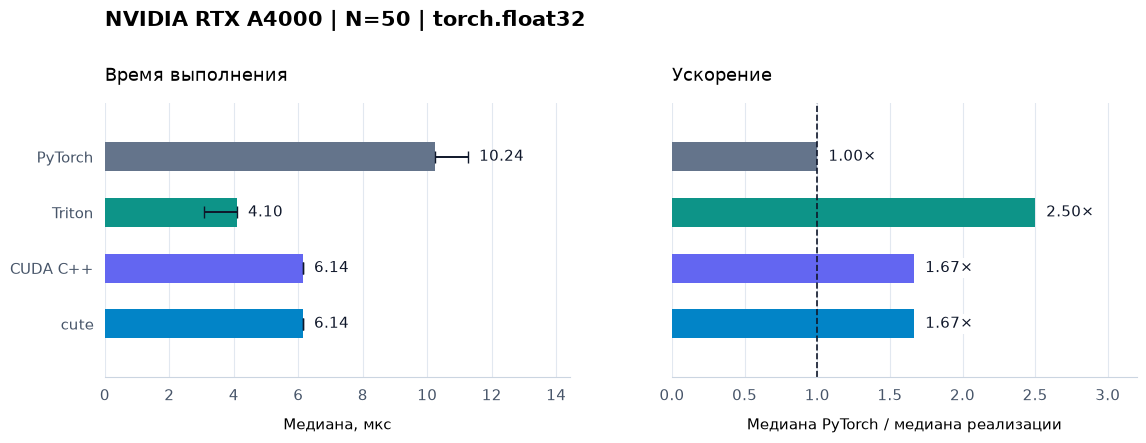

In [ ]:
fig = plot_benchmark(
    results,
    title=f"{torch.cuda.get_device_name(device)} | N={N:,} | {DTYPE}",
)
plt.show()
